**Purpose:** Imports libraries for threshold-based segmentation and visualization.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**Purpose:** Defines global thresholding that converts pixels to binary values.

In [2]:
def global_threshold(img, threshold):

    rows, cols = img.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(rows):
        for j in range(cols):

            if img[i, j] >= threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0

    return result

**Purpose:** Defines adaptive thresholding based on each pixel neighborhood mean.

In [3]:
def adaptive_threshold(img, block_size, C):

    rows, cols = img.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    half = block_size // 2

    for i in range(half, rows - half):
        for j in range(half, cols - half):

            region = img[
                i-half:i+half+1,
                j-half:j+half+1
            ]

            local_mean = np.mean(region)
            threshold = local_mean - C

            if img[i, j] >= threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0

    return result


**Purpose:** Defines region growing from a seed using a pixel-intensity tolerance.

In [4]:
def region_growing(img, seed_x, seed_y, threshold):

    rows, cols = img.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    seed_value = int(img[seed_x, seed_y])

    stack = [(seed_x, seed_y)]
    result[seed_x, seed_y] = 255

    while len(stack) > 0:

        x, y = stack.pop()

        # Check 4 neighboring pixels
        neighbors = [
            (x-1, y),
            (x+1, y),
            (x, y-1),
            (x, y+1)
        ]

        for nx, ny in neighbors:

            if 0 <= nx < rows and 0 <= ny < cols:

                if result[nx, ny] == 0:

                    difference = abs(
                        int(img[nx, ny]) - seed_value
                    )

                    if difference <= threshold:

                        result[nx, ny] = 255
                        stack.append((nx, ny))

    return result


**Purpose:** Runs global and adaptive thresholding plus region growing, then displays each result.

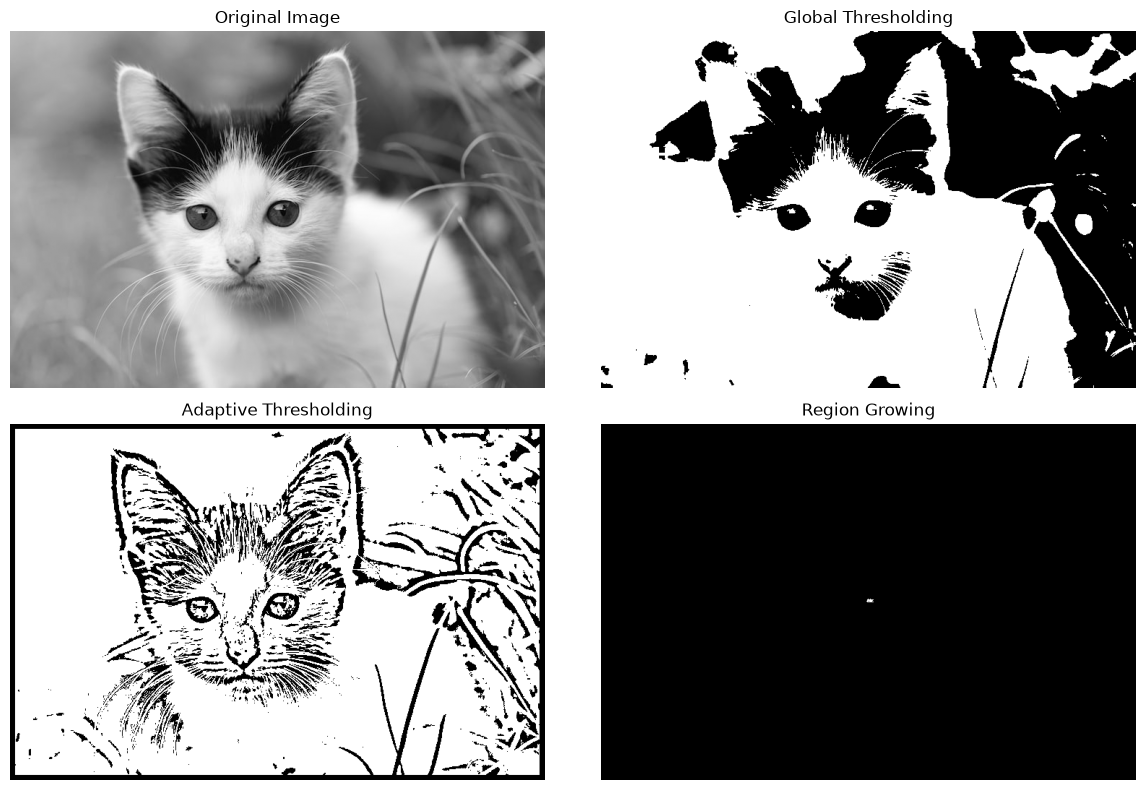

In [5]:
img = cv2.imread("../cat.jpg", 0)

if img is None:
    print("Image not found!")
    exit()


# Apply Thresholding
global_result = global_threshold(img, 127)

adaptive_result = adaptive_threshold(
    img, block_size=15, C=5
)


# Apply Region Growing
region_result = region_growing(
    img,
    seed_x=img.shape[0] // 2,
    seed_y=img.shape[1] // 2,
    threshold=20
)


# Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(global_result, cmap='gray')
plt.title("Global Thresholding")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(adaptive_result, cmap='gray')
plt.title("Adaptive Thresholding")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(region_result, cmap='gray')
plt.title("Region Growing")
plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.